In [4]:
# ============================================================
# STEP 1: Environment setup
# ============================================================
import os, random, time, pickle, re, glob, json
import numpy as np
import tensorflow as tf
import h5py
import cv2
from collections import Counter
import matplotlib.pyplot as plt

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow version: {tf.__version__}")

gpus = tf.config.list_physical_devices('GPU')
print(f"Num GPUs detected: {len(gpus)}")
if len(gpus) == 0:
    raise RuntimeError("No GPU detected! Settings -> Accelerator -> GPU T4 x2 -> restart session.")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

# Staying in float32 deliberately - mixed_float16 caused a NaN explosion earlier
# (likely a BatchNorm/float16 interaction under Keras 3). Correctness over speed.
strategy = tf.distribute.MirroredStrategy() if len(gpus) > 1 else tf.distribute.get_strategy()
print(f"Replicas in strategy: {strategy.num_replicas_in_sync}")

DATASET_DIR = "/kaggle/input/datasets/mohammadzaimullah/figshare-dataset"
print("Dataset exists:", os.path.exists(DATASET_DIR))


# ============================================================
# STEP 2: Parse .mat files
# ============================================================
SUBDIRS = ["brainTumorDataPublic_1-766", "brainTumorDataPublic_767-1532",
           "brainTumorDataPublic_1533-2298", "brainTumorDataPublic_2299-3064"]
LABEL_MAP = {1: "meningioma", 2: "glioma", 3: "pituitary"}

all_paths = []
for sub in SUBDIRS:
    all_paths.extend(glob.glob(os.path.join(DATASET_DIR, sub, "*.mat")))

def file_index(p):
    return int(re.search(r"(\d+)\.mat$", os.path.basename(p)).group(1))
all_paths = sorted(all_paths, key=file_index)
assert len(all_paths) == 3064, f"Expected 3064, found {len(all_paths)}"

images, labels, pids = [], [], []
t0 = time.time()
for path in all_paths:
    with h5py.File(path, 'r') as f:
        cj = f['cjdata']
        labels.append(int(np.array(cj['label']).item()))
        images.append(np.array(cj['image']).T.astype(np.float32))
        pid_raw = np.array(cj['PID']).flatten()
        try:
            pids.append(''.join(chr(int(c)) for c in pid_raw))
        except Exception:
            pids.append(str(pid_raw.tobytes()))
print(f"Parsed {len(images)} images in {time.time()-t0:.1f}s")
print("Class distribution:", Counter(labels))


# ============================================================
# STEP 3: Preprocess - resize, normalize, channel conversion (224x224, fixed)
# ============================================================
from tensorflow.keras.applications.resnet50 import preprocess_input

TARGET_SIZE = 224
NUM_CLASSES = 3

def normalize_image(img, low_pct=0.5, high_pct=99.5):
    lo, hi = np.percentile(img, low_pct), np.percentile(img, high_pct)
    if hi <= lo:
        hi, lo = img.max(), img.min()
    img = np.clip(img, lo, hi)
    return ((img - lo) / (hi - lo + 1e-8) * 255.0).astype(np.float32)

X_resized = np.zeros((len(images), TARGET_SIZE, TARGET_SIZE, 3), dtype=np.float32)
for i, img in enumerate(images):
    norm = normalize_image(img)
    resized = cv2.resize(norm, (TARGET_SIZE, TARGET_SIZE), interpolation=cv2.INTER_AREA)
    X_resized[i] = np.stack([resized, resized, resized], axis=-1)

X_preprocessed = preprocess_input(X_resized.copy())
del X_resized

LABEL_TO_IDX = {1: 0, 2: 1, 3: 2}
y_encoded = np.array([LABEL_TO_IDX[l] for l in labels], dtype=np.int32)
print(f"X_preprocessed: {X_preprocessed.shape}, y_encoded: {y_encoded.shape}")
print("Class distribution:", Counter(y_encoded.tolist()))


# ============================================================
# STEP 4: Stratified 10-Fold split + tf.data pipeline
# ============================================================
from sklearn.model_selection import StratifiedKFold

N_FOLDS = 10
BATCH_SIZE = 16

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
fold_indices = list(skf.split(X_preprocessed, y_encoded))
with open("/kaggle/working/fold_indices.pkl", "wb") as f:
    pickle.dump(fold_indices, f)

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.04),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(0.05, 0.05),
    tf.keras.layers.RandomContrast(0.1),
], name="data_augmentation")

def make_dataset(X, y, batch_size, training=True):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(buffer_size=len(X), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(batch_size)
    if training:
        ds = ds.map(
            lambda xb, yb: (tf.cast(data_augmentation(xb, training=True), tf.float32), yb),
            num_parallel_calls=tf.data.AUTOTUNE
        )
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

# Sanity check
train_idx, val_idx = fold_indices[0]
train_ds_test = make_dataset(X_preprocessed[train_idx], y_encoded[train_idx], BATCH_SIZE, True)
for xb, yb in train_ds_test.take(1):
    print(f"Sanity check - train batch: x={xb.shape}, dtype={xb.dtype}")
del train_ds_test

print("\n✅ Steps 1-4 complete.")

TensorFlow version: 2.19.0
Num GPUs detected: 2
INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
Replicas in strategy: 2
Dataset exists: True
Parsed 3064 images in 31.9s
Class distribution: Counter({2: 1426, 3: 930, 1: 708})
X_preprocessed: (3064, 224, 224, 3), y_encoded: (3064,)
Class distribution: Counter({1: 1426, 2: 930, 0: 708})
Sanity check - train batch: x=(16, 224, 224, 3), dtype=<dtype: 'float32'>

✅ Steps 1-4 complete.


In [5]:
# ============================================================
# STEP 5: Model architecture, LR schedule, optimizer, callbacks
# ============================================================
CHECKPOINT_DIR = "/kaggle/working/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

TOTAL_EPOCHS = 30
WARMUP_EPOCHS = 3
PEAK_LR = 1e-4          # lowered from 1e-3 - original value caused a NaN explosion
MIN_LR_ALPHA = 0.01
WEIGHT_DECAY = 1e-4
EPSILON = 1.0           # FGSM step size
GLOBAL_BATCH_SIZE = BATCH_SIZE
RESULTS_PATH = "/kaggle/working/fold_results.json"

# ---- Class weights (inverse frequency) ----
class_counts = Counter(y_encoded.tolist())
n_total = len(y_encoded)
class_weights_arr = np.array(
    [n_total / (NUM_CLASSES * class_counts[i]) for i in range(NUM_CLASSES)], dtype=np.float32
)
print("Class weights (meningioma, glioma, pituitary):", class_weights_arr)
CLASS_WEIGHTS_TENSOR = tf.constant(class_weights_arr)


def build_resnet_dual_output(input_shape=(224, 224, 3), num_classes=NUM_CLASSES):
    """Full fine-tune: only BatchNorm frozen. This is the validated recipe (0.9381 on fold 0)."""
    inputs = tf.keras.Input(shape=input_shape, name="input_image")
    backbone = tf.keras.applications.ResNet50(
        weights="imagenet", include_top=False, input_tensor=inputs, pooling=None
    )
    n_frozen_bn = 0
    for layer in backbone.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False
            n_frozen_bn += 1
        else:
            layer.trainable = True

    feat_map = backbone.output
    embedding = tf.keras.layers.GlobalAveragePooling2D(name="embedding")(feat_map)
    x = tf.keras.layers.Dropout(0.4)(embedding)
    logits = tf.keras.layers.Dense(
        num_classes, dtype='float32', name="logits",
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    )(x)
    model = tf.keras.Model(inputs=inputs, outputs=[logits, embedding], name="resnet50_dual_output")
    return model, n_frozen_bn


class AdversarialNSLModel(tf.keras.Model):
    def __init__(self, base_model, epsilon=1.0, lambda_adv=0.2, lambda_emb=0.1,
                 global_batch_size=16, class_weights_tensor=None, num_classes=NUM_CLASSES, **kwargs):
        super().__init__(**kwargs)
        self.base_model = base_model
        self.epsilon = epsilon
        self.lambda_adv = lambda_adv
        self.lambda_emb = lambda_emb
        self.global_batch_size = global_batch_size
        self.class_weights_tensor = class_weights_tensor
        self.num_classes = num_classes
        # label_smoothing requires CategoricalCrossentropy (one-hot), not Sparse
        self.cce = tf.keras.losses.CategoricalCrossentropy(
            from_logits=True, label_smoothing=0.05, reduction=tf.keras.losses.Reduction.NONE
        )
        self.loss_tracker = tf.keras.metrics.Mean(name="loss")
        self.acc_tracker = tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")
        self.adv_acc_tracker = tf.keras.metrics.SparseCategoricalAccuracy(name="adv_accuracy")

    def call(self, inputs, training=False):
        return self.base_model(inputs, training=training)

    def _avg(self, per_example_loss):
        return tf.nn.compute_average_loss(per_example_loss, global_batch_size=self.global_batch_size)

    def _sample_weights(self, y_sparse):
        if self.class_weights_tensor is None:
            return 1.0
        return tf.gather(self.class_weights_tensor, y_sparse)

    def train_step(self, data):
        x, y = data
        y_onehot = tf.one_hot(y, depth=self.num_classes, dtype=tf.float32)
        sw = self._sample_weights(y)

        with tf.GradientTape() as tape_fgsm:
            tape_fgsm.watch(x)
            logits_tmp, _ = self.base_model(x, training=True)
            pe_loss_tmp = self.cce(y_onehot, logits_tmp)
            local_loss_for_grad = tf.reduce_mean(pe_loss_tmp)
        grad_x = tape_fgsm.gradient(local_loss_for_grad, x)
        perturbation = self.epsilon * tf.sign(grad_x)
        x_adv = tf.stop_gradient(x + perturbation)

        with tf.GradientTape() as tape:
            logits_clean, emb_clean = self.base_model(x, training=True)
            logits_adv, emb_adv = self.base_model(x_adv, training=True)

            pe_loss_clean = self.cce(y_onehot, logits_clean) * sw
            pe_loss_adv = self.cce(y_onehot, logits_adv) * sw
            loss_clean = self._avg(pe_loss_clean)
            loss_adv = self._avg(pe_loss_adv)

            emb_clean_norm = tf.nn.l2_normalize(tf.cast(emb_clean, tf.float32), axis=-1)
            emb_adv_norm = tf.nn.l2_normalize(tf.cast(emb_adv, tf.float32), axis=-1)
            pe_emb_reg = tf.reduce_sum(tf.square(emb_clean_norm - emb_adv_norm), axis=-1)
            emb_reg = self._avg(pe_emb_reg)

            total_loss = loss_clean + self.lambda_adv * loss_adv + self.lambda_emb * emb_reg
            if self.base_model.losses:
                total_loss += tf.add_n(self.base_model.losses)

        gradients = tape.gradient(total_loss, self.base_model.trainable_variables)
        self.optimizer.apply_gradients(zip(gradients, self.base_model.trainable_variables))

        self.loss_tracker.update_state(total_loss)
        self.acc_tracker.update_state(y, logits_clean)
        self.adv_acc_tracker.update_state(y, logits_adv)
        return {"loss": self.loss_tracker.result(), "accuracy": self.acc_tracker.result(),
                "adv_accuracy": self.adv_acc_tracker.result()}

    def test_step(self, data):
        x, y = data
        y_onehot = tf.one_hot(y, depth=self.num_classes, dtype=tf.float32)
        logits, emb = self.base_model(x, training=False)
        pe_loss = self.cce(y_onehot, logits)
        loss = self._avg(pe_loss)
        self.loss_tracker.update_state(loss)
        self.acc_tracker.update_state(y, logits)
        return {"loss": self.loss_tracker.result(), "accuracy": self.acc_tracker.result()}

    @property
    def metrics(self):
        return [self.loss_tracker, self.acc_tracker, self.adv_acc_tracker]


def build_lr_schedule(steps_per_epoch, total_epochs=TOTAL_EPOCHS, warmup_epochs=WARMUP_EPOCHS):
    warmup_steps = steps_per_epoch * warmup_epochs
    decay_steps = steps_per_epoch * (total_epochs - warmup_epochs)
    return tf.keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=PEAK_LR * 0.01, decay_steps=decay_steps,
        alpha=MIN_LR_ALPHA, warmup_target=PEAK_LR, warmup_steps=warmup_steps,
    )

def build_optimizer(lr_schedule):
    return tf.keras.optimizers.AdamW(
        learning_rate=lr_schedule, weight_decay=WEIGHT_DECAY,
        beta_1=0.9, beta_2=0.999, clipnorm=1.0
    )

def build_callbacks(fold_i):
    ckpt_path = os.path.join(CHECKPOINT_DIR, f"fold_{fold_i}_best.weights.h5")
    return [
        tf.keras.callbacks.TerminateOnNaN(),
        tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=10,
                                           restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(filepath=ckpt_path, monitor="val_accuracy", mode="max",
                                             save_best_only=True, save_weights_only=True, verbose=0),
    ]

print("✅ Step 5 defined: full fine-tune + class weights + label smoothing + L2.")

Class weights (meningioma, glioma, pituitary): [1.4425611 0.7162225 1.0982078]
✅ Step 5 defined: full fine-tune + class weights + label smoothing + L2.


In [6]:
# ============================================================
# STEP 6: 10-Fold training loop - resumable
# ============================================================

if os.path.exists(RESULTS_PATH):
    with open(RESULTS_PATH, "r") as f:
        fold_results = json.load(f)
    print(f"Resuming - {len(fold_results)} fold(s) already completed.")
else:
    fold_results = {}

for fold_i, (train_idx, val_idx) in enumerate(fold_indices):
    fold_key = str(fold_i)
    ckpt_path = os.path.join(CHECKPOINT_DIR, f"fold_{fold_i}_best.weights.h5")

    if fold_key in fold_results and os.path.exists(ckpt_path):
        print(f"Fold {fold_i}: already done (val_accuracy={fold_results[fold_key]['best_val_accuracy']:.4f}). Skipping.")
        continue

    print(f"\n{'='*60}\nFOLD {fold_i}/{len(fold_indices)-1}\n{'='*60}")
    t0 = time.time()

    X_train, y_train = X_preprocessed[train_idx], y_encoded[train_idx]
    X_val, y_val = X_preprocessed[val_idx], y_encoded[val_idx]
    train_ds = make_dataset(X_train, y_train, BATCH_SIZE, training=True)
    val_ds = make_dataset(X_val, y_val, BATCH_SIZE, training=False)

    steps_per_epoch = len(train_idx) // BATCH_SIZE
    lr_schedule = build_lr_schedule(steps_per_epoch)

    with strategy.scope():
        backbone, n_frozen_bn = build_resnet_dual_output()
        nsl_model = AdversarialNSLModel(
            base_model=backbone, epsilon=EPSILON, lambda_adv=0.2, lambda_emb=0.1,
            global_batch_size=BATCH_SIZE, class_weights_tensor=CLASS_WEIGHTS_TENSOR
        )
        optimizer = build_optimizer(lr_schedule)
        nsl_model.compile(optimizer=optimizer)

    history = nsl_model.fit(
        train_ds, epochs=TOTAL_EPOCHS, validation_data=val_ds,
        callbacks=build_callbacks(fold_i), verbose=2
    )

    best_val_acc = max(history.history["val_accuracy"])
    elapsed = time.time() - t0
    fold_results[fold_key] = {
        "best_val_accuracy": float(best_val_acc),
        "final_val_loss": float(history.history["val_loss"][-1]),
        "epochs_trained": len(history.history["loss"]),
        "train_time_sec": elapsed,
    }
    with open(RESULTS_PATH, "w") as f:
        json.dump(fold_results, f, indent=2)

    print(f"Fold {fold_i} done in {elapsed/60:.1f} min - best val_accuracy={best_val_acc:.4f}")

    del nsl_model, backbone, train_ds, val_ds
    tf.keras.backend.clear_session()

print("\n✅ All folds trained.")
print(json.dumps(fold_results, indent=2))


FOLD 0/9
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
Epoch 1/30
INFO:tensorflow:Collective all_reduce tensors: 108 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
173/173 - 119s - 687ms/step - accuracy: 0.6779 - adv_accuracy: 0.3348 - loss: 0.5568 - val_accuracy: 0.5178 - val_loss: 0.4812
Epoch 2/30
173/173 - 66s - 381ms/step - accuracy: 0.8676 - adv_accuracy: 0.5988 - loss: 0.3473 - val_accuracy: 0.8272 - val_loss: 0.2567
Epoch 3/30
173/173 - 66s - 382ms/step - accuracy: 0.8926 - adv_accuracy: 0.7283 - loss: 0.2930 - val_accuracy: 0.8306 - val_loss: 0.2499
Epoch 4/30
173/173 - 66s - 382ms/step - accuracy: 0.9213 - adv_accuracy: 0.7777 - loss: 0.2550 - val_accuracy: 0.8957 - val_loss: 0.2097

Per-fold best validation accuracy:
  Fold 0: 0.9446
  Fold 1: 0.8763
  Fold 2: 0.9316
  Fold 3: 0.9413
  Fold 4: 0.9314
  Fold 5: 0.9314
  Fold 6: 0.9118
  Fold 7: 0.8824
  Fold 8: 0.9314
  Fold 9: 0.9346

Mean CV accuracy: 0.9217 ± 0.0227
Min: 0.8763 (fold 1)  |  Max: 0.9446 (fold 0)


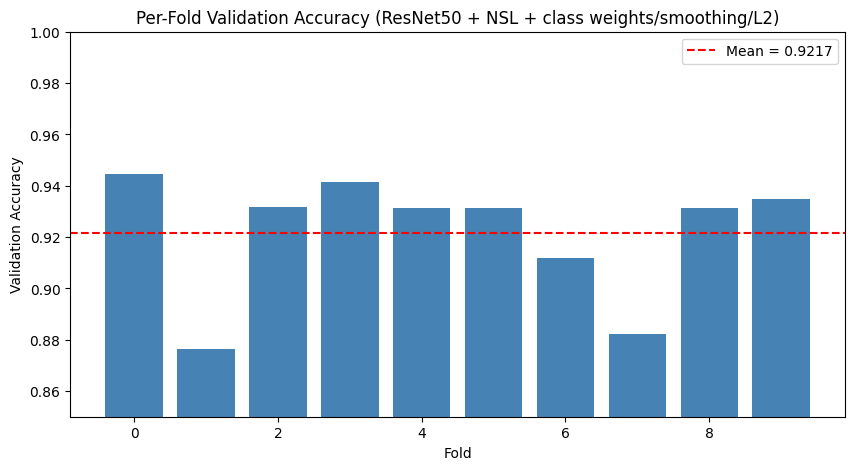

In [7]:
# ============================================================
# STEP 7: Aggregate fold metrics
# ============================================================
val_accs = [fold_results[str(i)]["best_val_accuracy"] for i in range(N_FOLDS)]
mean_acc, std_acc = np.mean(val_accs), np.std(val_accs)

print("Per-fold best validation accuracy:")
for i, acc in enumerate(val_accs):
    print(f"  Fold {i}: {acc:.4f}")
print(f"\nMean CV accuracy: {mean_acc:.4f} ± {std_acc:.4f}")
print(f"Min: {min(val_accs):.4f} (fold {np.argmin(val_accs)})  |  Max: {max(val_accs):.4f} (fold {np.argmax(val_accs)})")

plt.figure(figsize=(10, 5))
plt.bar(range(N_FOLDS), val_accs, color='steelblue')
plt.axhline(mean_acc, color='red', linestyle='--', label=f'Mean = {mean_acc:.4f}')
plt.xlabel("Fold"); plt.ylabel("Validation Accuracy")
plt.title("Per-Fold Validation Accuracy (ResNet50 + NSL + class weights/smoothing/L2)")
plt.ylim(0.85, 1.0)
plt.legend()
plt.savefig("/kaggle/working/fold_accuracy_bar.png", dpi=100)
plt.show()

In [ ]:
# ============================================================
# STEP 8: TTA + Out-of-Fold ensemble predictions
# ============================================================
def tta_predict(model, X_batch):
    views = [
        X_batch,
        tf.image.flip_left_right(X_batch),
        tf.image.adjust_brightness(X_batch, delta=5.0),
        tf.image.adjust_brightness(X_batch, delta=-5.0),
    ]
    all_probs = []
    for v in views:
        logits, _ = model(v, training=False)
        all_probs.append(tf.nn.softmax(tf.cast(logits, tf.float32), axis=-1))
    return tf.reduce_mean(tf.stack(all_probs, axis=0), axis=0)

oof_probs = np.zeros((len(y_encoded), NUM_CLASSES), dtype=np.float32)
oof_filled = np.zeros(len(y_encoded), dtype=bool)

for fold_i, (train_idx, val_idx) in enumerate(fold_indices):
    ckpt_path = os.path.join(CHECKPOINT_DIR, f"fold_{fold_i}_best.weights.h5")
    print(f"Fold {fold_i}: predicting on {len(val_idx)} held-out samples...")

    with strategy.scope():
        backbone, _ = build_resnet_dual_output()
        nsl_model = AdversarialNSLModel(base_model=backbone, global_batch_size=BATCH_SIZE)
        _ = nsl_model(tf.zeros((1, 224, 224, 3)), training=False)
    nsl_model.load_weights(ckpt_path)

    X_val = X_preprocessed[val_idx]
    fold_probs = []
    for start in range(0, len(X_val), BATCH_SIZE):
        batch = X_val[start:start + BATCH_SIZE]
        fold_probs.append(tta_predict(nsl_model, batch).numpy())
    fold_probs = np.concatenate(fold_probs, axis=0)

    oof_probs[val_idx] = fold_probs
    oof_filled[val_idx] = True

    del nsl_model, backbone
    tf.keras.backend.clear_session()

assert oof_filled.all(), "Some samples never got predicted!"
oof_preds = np.argmax(oof_probs, axis=1)

np.save("/kaggle/working/oof_probs.npy", oof_probs)
np.save("/kaggle/working/oof_preds.npy", oof_preds)

oof_accuracy = (oof_preds == y_encoded).mean()
print(f"\nOverall OOF accuracy (TTA, leakage-free, full 3064-image dataset): {oof_accuracy:.4f}")

In [ ]:
# ============================================================
# STEP 9: Classification report - the real comparison point
# ============================================================
from sklearn.metrics import classification_report

CLASS_NAMES = ["meningioma", "glioma", "pituitary"]
report = classification_report(y_encoded, oof_preds, target_names=CLASS_NAMES, digits=4)
print("Classification Report (Out-of-Fold, TTA, class weights + label smoothing + L2):\n")
print(report)


In [ ]:
# ============================================================
# Free test: wider TTA on existing fold checkpoints (no retraining)
# ============================================================
def tta_predict_wide(model, X_batch):
    views = [
        X_batch,
        tf.image.flip_left_right(X_batch),
        tf.image.adjust_brightness(X_batch, delta=5.0),
        tf.image.adjust_brightness(X_batch, delta=-5.0),
        tf.image.adjust_contrast(X_batch, contrast_factor=1.1),
        tf.image.adjust_contrast(X_batch, contrast_factor=0.9),
    ]
    all_probs = []
    for v in views:
        logits, _ = model(v, training=False)
        all_probs.append(tf.nn.softmax(tf.cast(logits, tf.float32), axis=-1))
    return tf.reduce_mean(tf.stack(all_probs, axis=0), axis=0)

oof_probs_wide = np.zeros((len(y_encoded), NUM_CLASSES), dtype=np.float32)

for fold_i, (train_idx, val_idx) in enumerate(fold_indices):
    ckpt_path = os.path.join(CHECKPOINT_DIR, f"fold_{fold_i}_best.weights.h5")
    with strategy.scope():
        backbone, _ = build_resnet_dual_output()
        nsl_model = AdversarialNSLModel(base_model=backbone, global_batch_size=BATCH_SIZE)
        _ = nsl_model(tf.zeros((1, 224, 224, 3)), training=False)
    nsl_model.load_weights(ckpt_path)

    X_val = X_preprocessed[val_idx]
    fold_probs = []
    for start in range(0, len(X_val), BATCH_SIZE):
        batch = X_val[start:start + BATCH_SIZE]
        fold_probs.append(tta_predict_wide(nsl_model, batch).numpy())
    oof_probs_wide[val_idx] = np.concatenate(fold_probs, axis=0)

    del nsl_model, backbone
    tf.keras.backend.clear_session()

oof_preds_wide = np.argmax(oof_probs_wide, axis=1)
acc_wide = (oof_preds_wide == y_encoded).mean()
print(f"Wider TTA (6 views): {acc_wide:.4f}")
print(f"Current TTA (4 views): {oof_accuracy:.4f}")

In [8]:
# ============================================================
# STEP 10: Preprocess for EfficientNetB0 (different input convention than ResNet50)
# ============================================================
X_eff = np.zeros((len(images), TARGET_SIZE, TARGET_SIZE, 3), dtype=np.float32)
for i, img in enumerate(images):
    norm = normalize_image(img)  # reuses the same percentile-clip function from Step 3
    resized = cv2.resize(norm, (TARGET_SIZE, TARGET_SIZE), interpolation=cv2.INTER_AREA)
    X_eff[i] = np.stack([resized, resized, resized], axis=-1)

# No preprocess_input call here - EfficientNetB0 has built-in rescaling,
# it expects raw [0, 255] float input, unlike ResNet50's mean-subtracted convention.
print(f"X_eff shape: {X_eff.shape}, range: [{X_eff.min():.2f}, {X_eff.max():.2f}]")
print("(Should be [0, 255] - if this looks like ResNet's [-124, 151] range, something's wrong.)")

X_eff shape: (3064, 224, 224, 3), range: [0.00, 255.00]
(Should be [0, 255] - if this looks like ResNet's [-124, 151] range, something's wrong.)


In [9]:
# ============================================================
# STEP 11: EfficientNetB0 dual-output model + smoke test
# ============================================================
CHECKPOINT_DIR_EFF = "/kaggle/working/checkpoints_efficientnet"
os.makedirs(CHECKPOINT_DIR_EFF, exist_ok=True)
RESULTS_PATH_EFF = "/kaggle/working/fold_results_efficientnet.json"

def build_efficientnet_dual_output(input_shape=(224, 224, 3), num_classes=NUM_CLASSES):
    """Same design as the ResNet50 builder: full fine-tune, only BN frozen."""
    inputs = tf.keras.Input(shape=input_shape, name="input_image")
    backbone = tf.keras.applications.EfficientNetB0(
        weights="imagenet", include_top=False, input_tensor=inputs, pooling=None
    )
    n_frozen_bn = 0
    for layer in backbone.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False
            n_frozen_bn += 1
        else:
            layer.trainable = True

    feat_map = backbone.output
    embedding = tf.keras.layers.GlobalAveragePooling2D(name="embedding")(feat_map)
    x = tf.keras.layers.Dropout(0.4)(embedding)
    logits = tf.keras.layers.Dense(
        num_classes, dtype='float32', name="logits",
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    )(x)
    model = tf.keras.Model(inputs=inputs, outputs=[logits, embedding], name="efficientnetb0_dual_output")
    return model, n_frozen_bn


def build_callbacks_eff(fold_i):
    ckpt_path = os.path.join(CHECKPOINT_DIR_EFF, f"fold_{fold_i}_best.weights.h5")
    return [
        tf.keras.callbacks.TerminateOnNaN(),
        tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=10,
                                           restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(filepath=ckpt_path, monitor="val_accuracy", mode="max",
                                             save_best_only=True, save_weights_only=True, verbose=0),
    ]


# ---- Smoke test on fold 0 (reusing AdversarialNSLModel, build_lr_schedule, build_optimizer - architecture-agnostic) ----
train_idx, val_idx = fold_indices[0]
X_train_eff, y_train = X_eff[train_idx], y_encoded[train_idx]
X_val_eff, y_val = X_eff[val_idx], y_encoded[val_idx]
train_ds_eff_test = make_dataset(X_train_eff, y_train, BATCH_SIZE, training=True)
val_ds_eff_test = make_dataset(X_val_eff, y_val, BATCH_SIZE, training=False)

with strategy.scope():
    backbone_eff, n_frozen_bn_eff = build_efficientnet_dual_output()
    test_model_eff = AdversarialNSLModel(
        base_model=backbone_eff, epsilon=EPSILON, lambda_adv=0.2, lambda_emb=0.1,
        global_batch_size=BATCH_SIZE, class_weights_tensor=CLASS_WEIGHTS_TENSOR
    )
    test_model_eff.compile(optimizer=build_optimizer(1e-4))

total_params_eff = backbone_eff.count_params()
trainable_eff = sum(tf.size(w).numpy() for w in backbone_eff.trainable_weights)
print(f"EfficientNetB0 total params: {total_params_eff:,} | trainable: {trainable_eff:,} | frozen BN: {n_frozen_bn_eff}")

print("\n--- Smoke test: 20 train steps, 5 val steps ---")
test_model_eff.fit(train_ds_eff_test, epochs=1, steps_per_epoch=20,
                     validation_data=val_ds_eff_test, validation_steps=5, verbose=1)

del test_model_eff, backbone_eff, train_ds_eff_test, val_ds_eff_test
tf.keras.backend.clear_session()
print("\n✅ Step 11 complete if loss is finite and EfficientNetB0 downloaded/built without error.")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 total params: 4,053,414 | trainable: 3,969,375 | frozen BN: 49

--- Smoke test: 20 train steps, 5 val steps ---
INFO:tensorflow:Collective all_reduce tensors: 115 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1


E0000 00:00:1782667055.018275      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/efficientnetb0_dual_output_3/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


20/20 ━━━━━━━━━━━━━━━━━━━━ 66s 567ms/step - accuracy: 0.5531 - adv_accuracy: 0.1156 - loss: 0.6830 - val_accuracy: 0.6000 - val_loss: 0.4673

✅ Step 11 complete if loss is finite and EfficientNetB0 downloaded/built without error.


In [10]:
# ============================================================
# STEP 12: 10-Fold training loop - EfficientNetB0, resumable
# ============================================================

if os.path.exists(RESULTS_PATH_EFF):
    with open(RESULTS_PATH_EFF, "r") as f:
        fold_results_eff = json.load(f)
    print(f"Resuming - {len(fold_results_eff)} fold(s) already completed.")
else:
    fold_results_eff = {}

for fold_i, (train_idx, val_idx) in enumerate(fold_indices):
    fold_key = str(fold_i)
    ckpt_path = os.path.join(CHECKPOINT_DIR_EFF, f"fold_{fold_i}_best.weights.h5")

    if fold_key in fold_results_eff and os.path.exists(ckpt_path):
        print(f"Fold {fold_i}: already done (val_accuracy={fold_results_eff[fold_key]['best_val_accuracy']:.4f}). Skipping.")
        continue

    print(f"\n{'='*60}\nFOLD {fold_i}/{len(fold_indices)-1}  (EfficientNetB0)\n{'='*60}")
    t0 = time.time()

    X_train_eff, y_train = X_eff[train_idx], y_encoded[train_idx]
    X_val_eff, y_val = X_eff[val_idx], y_encoded[val_idx]
    train_ds_eff = make_dataset(X_train_eff, y_train, BATCH_SIZE, training=True)
    val_ds_eff = make_dataset(X_val_eff, y_val, BATCH_SIZE, training=False)

    steps_per_epoch = len(train_idx) // BATCH_SIZE
    lr_schedule = build_lr_schedule(steps_per_epoch)

    with strategy.scope():
        backbone_eff, _ = build_efficientnet_dual_output()
        nsl_model_eff = AdversarialNSLModel(
            base_model=backbone_eff, epsilon=EPSILON, lambda_adv=0.2, lambda_emb=0.1,
            global_batch_size=BATCH_SIZE, class_weights_tensor=CLASS_WEIGHTS_TENSOR
        )
        optimizer = build_optimizer(lr_schedule)
        nsl_model_eff.compile(optimizer=optimizer)

    history = nsl_model_eff.fit(
        train_ds_eff, epochs=TOTAL_EPOCHS, validation_data=val_ds_eff,
        callbacks=build_callbacks_eff(fold_i), verbose=2
    )

    best_val_acc = max(history.history["val_accuracy"])
    elapsed = time.time() - t0
    fold_results_eff[fold_key] = {
        "best_val_accuracy": float(best_val_acc),
        "final_val_loss": float(history.history["val_loss"][-1]),
        "epochs_trained": len(history.history["loss"]),
        "train_time_sec": elapsed,
    }
    with open(RESULTS_PATH_EFF, "w") as f:
        json.dump(fold_results_eff, f, indent=2)

    print(f"Fold {fold_i} done in {elapsed/60:.1f} min - best val_accuracy={best_val_acc:.4f}")

    del nsl_model_eff, backbone_eff, train_ds_eff, val_ds_eff
    tf.keras.backend.clear_session()

print("\n✅ All EfficientNetB0 folds trained.")
print(json.dumps(fold_results_eff, indent=2))


FOLD 0/9  (EfficientNetB0)
Epoch 1/30
INFO:tensorflow:Collective all_reduce tensors: 115 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1


E0000 00:00:1782667149.568198      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/efficientnetb0_dual_output_3/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


173/173 - 121s - 699ms/step - accuracy: 0.5771 - adv_accuracy: 0.1201 - loss: 0.6542 - val_accuracy: 0.8012 - val_loss: 0.2929
Epoch 2/30
173/173 - 48s - 278ms/step - accuracy: 0.8556 - adv_accuracy: 0.4469 - loss: 0.3745 - val_accuracy: 0.9120 - val_loss: 0.1859
Epoch 3/30
173/173 - 48s - 275ms/step - accuracy: 0.9057 - adv_accuracy: 0.6065 - loss: 0.2822 - val_accuracy: 0.9282 - val_loss: 0.1629
Epoch 4/30
173/173 - 49s - 283ms/step - accuracy: 0.9441 - adv_accuracy: 0.7240 - loss: 0.2283 - val_accuracy: 0.9511 - val_loss: 0.1361
Epoch 5/30
173/173 - 49s - 282ms/step - accuracy: 0.9655 - adv_accuracy: 0.7947 - loss: 0.1949 - val_accuracy: 0.9543 - val_loss: 0.1322
Epoch 6/30
173/173 - 48s - 280ms/step - accuracy: 0.9706 - adv_accuracy: 0.8397 - loss: 0.1717 - val_accuracy: 0.9608 - val_loss: 0.1206
Epoch 7/30
173/173 - 48s - 279ms/step - accuracy: 0.9797 - adv_accuracy: 0.8607 - loss: 0.1598 - val_accuracy: 0.9804 - val_loss: 0.1022
Epoch 8/30
173/173 - 47s - 273ms/step - accuracy: 0

E0000 00:00:1782668050.313223      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/efficientnetb0_dual_output_3/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


173/173 - 118s - 679ms/step - accuracy: 0.6097 - adv_accuracy: 0.1066 - loss: 0.6383 - val_accuracy: 0.7557 - val_loss: 0.3183
Epoch 2/30
173/173 - 48s - 275ms/step - accuracy: 0.8513 - adv_accuracy: 0.4403 - loss: 0.3786 - val_accuracy: 0.8860 - val_loss: 0.2072
Epoch 3/30
173/173 - 47s - 269ms/step - accuracy: 0.9013 - adv_accuracy: 0.6166 - loss: 0.2864 - val_accuracy: 0.8762 - val_loss: 0.2380
Epoch 4/30
173/173 - 48s - 279ms/step - accuracy: 0.9412 - adv_accuracy: 0.7225 - loss: 0.2306 - val_accuracy: 0.9381 - val_loss: 0.1534
Epoch 5/30
173/173 - 48s - 279ms/step - accuracy: 0.9601 - adv_accuracy: 0.8001 - loss: 0.1929 - val_accuracy: 0.9674 - val_loss: 0.1293
Epoch 6/30
173/173 - 48s - 279ms/step - accuracy: 0.9724 - adv_accuracy: 0.8397 - loss: 0.1710 - val_accuracy: 0.9675 - val_loss: 0.1243
Epoch 7/30
173/173 - 48s - 279ms/step - accuracy: 0.9786 - adv_accuracy: 0.8636 - loss: 0.1585 - val_accuracy: 0.9707 - val_loss: 0.1182
Epoch 8/30
173/173 - 48s - 279ms/step - accuracy: 0

...

173/173 - 121s - 697ms/step - accuracy: 0.5370 - adv_accuracy: 0.1323 - loss: 0.6822 - val_accuracy: 0.8464 - val_loss: 0.2849
Epoch 2/30
173/173 - 48s - 280ms/step - accuracy: 0.8488 - adv_accuracy: 0.4402 - loss: 0.3813 - val_accuracy: 0.9510 - val_loss: 0.1601
Epoch 3/30
173/173 - 47s - 271ms/step - accuracy: 0.9141 - adv_accuracy: 0.6298 - loss: 0.2732 - val_accuracy: 0.9379 - val_loss: 0.1424
Epoch 4/30
173/173 - 48s - 280ms/step - accuracy: 0.9511 - adv_accuracy: 0.7382 - loss: 0.2167 - val_accuracy: 0.9641 - val_loss: 0.1279
Epoch 5/30
173/173 - 47s - 274ms/step - accuracy: 0.9616 - adv_accuracy: 0.7814 - loss: 0.1950 - val_accuracy: 0.9641 - val_loss: 0.1245
Epoch 6/30
173/173 - 48s - 279ms/step - accuracy: 0.9699 - adv_accuracy: 0.8372 - loss: 0.1727 - val_accuracy: 0.9706 - val_loss: 0.1116
Epoch 7/30
173/173 - 48s - 275ms/step - accuracy: 0.9750 - adv_accuracy: 0.8419 - loss: 0.1657 - val_accuracy: 0.9477 - val_loss: 0.1377
Epoch 8/30
173/173 - 47s - 274ms/step - accuracy: 0

E0000 00:00:1782676854.324859      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/efficientnetb0_dual_output_3/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


173/173 - 118s - 682ms/step - accuracy: 0.5685 - adv_accuracy: 0.1131 - loss: 0.6642 - val_accuracy: 0.7778 - val_loss: 0.2874
Epoch 2/30
173/173 - 48s - 275ms/step - accuracy: 0.8419 - adv_accuracy: 0.4637 - loss: 0.3850 - val_accuracy: 0.8824 - val_loss: 0.1851
Epoch 3/30
173/173 - 48s - 276ms/step - accuracy: 0.8992 - adv_accuracy: 0.6233 - loss: 0.2968 - val_accuracy: 0.9183 - val_loss: 0.1649
Epoch 4/30
173/173 - 48s - 279ms/step - accuracy: 0.9420 - adv_accuracy: 0.7331 - loss: 0.2270 - val_accuracy: 0.9477 - val_loss: 0.1327
Epoch 5/30
173/173 - 48s - 279ms/step - accuracy: 0.9601 - adv_accuracy: 0.7926 - loss: 0.1994 - val_accuracy: 0.9608 - val_loss: 0.1282
Epoch 6/30
173/173 - 48s - 279ms/step - accuracy: 0.9801 - adv_accuracy: 0.8445 - loss: 0.1675 - val_accuracy: 0.9641 - val_loss: 0.1306
Epoch 7/30
173/173 - 48s - 279ms/step - accuracy: 0.9790 - adv_accuracy: 0.8564 - loss: 0.1621 - val_accuracy: 0.9837 - val_loss: 0.1102
Epoch 8/30
173/173 - 48s - 275ms/step - accuracy: 0

E0000 00:00:1782678185.798530      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/efficientnetb0_dual_output_3/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


173/173 - 120s - 696ms/step - accuracy: 0.6099 - adv_accuracy: 0.1371 - loss: 0.6195 - val_accuracy: 0.8007 - val_loss: 0.2754
Epoch 2/30
173/173 - 48s - 279ms/step - accuracy: 0.8626 - adv_accuracy: 0.4576 - loss: 0.3743 - val_accuracy: 0.8595 - val_loss: 0.2138
Epoch 3/30
173/173 - 48s - 277ms/step - accuracy: 0.9050 - adv_accuracy: 0.5943 - loss: 0.3020 - val_accuracy: 0.9248 - val_loss: 0.1619
Epoch 4/30
173/173 - 48s - 280ms/step - accuracy: 0.9431 - adv_accuracy: 0.7223 - loss: 0.2340 - val_accuracy: 0.9542 - val_loss: 0.1498
Epoch 5/30
173/173 - 47s - 273ms/step - accuracy: 0.9634 - adv_accuracy: 0.7796 - loss: 0.1960 - val_accuracy: 0.9052 - val_loss: 0.1927
Epoch 6/30
173/173 - 49s - 281ms/step - accuracy: 0.9695 - adv_accuracy: 0.8267 - loss: 0.1831 - val_accuracy: 0.9706 - val_loss: 0.1192
Epoch 7/30
173/173 - 47s - 274ms/step - accuracy: 0.9779 - adv_accuracy: 0.8419 - loss: 0.1653 - val_accuracy: 0.9608 - val_loss: 0.1274
Epoch 8/30
173/173 - 48s - 276ms/step - accuracy: 0